In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# EDA

1. Общее описание данных:<br>
-  Датасет содержит 524,846 записей и 8 признаков и целевую переменную.<br>
-  Больше __500000__ писем являются __обычными__, то есть количество __фишинговых__ писем значительно меньше, чем обычных.<br>
-  Все признаки являются числовыми, что удобно.<br> 
-  Целевая переменная __label__ отвечает за информацию, является ли письмо фишинговым __(1, если оно является)__.

In [2]:
df = pd.read_csv("email_phishing_data.csv")
df.head(3)

,num_words,num_unique_words,num_stopwords,num_links,num_unique_domains,num_email_addresses,num_spelling_errors,num_urgent_keywords,label
0,140,94,52,0,0,0,0,0,0
1,5,5,1,0,0,0,0,0,0
2,34,32,15,0,0,0,0,0,0


In [3]:
df.shape

(524846, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 524846 entries, 0 to 524845
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   num_words            524846 non-null  int64
 1   num_unique_words     524846 non-null  int64
 2   num_stopwords        524846 non-null  int64
 3   num_links            524846 non-null  int64
 4   num_unique_domains   524846 non-null  int64
 5   num_email_addresses  524846 non-null  int64
 6   num_spelling_errors  524846 non-null  int64
 7   num_urgent_keywords  524846 non-null  int64
 8   label                524846 non-null  int64
dtypes: int64(9)
memory usage: 36.0 MB


In [5]:
df.isnull().sum()

num_words              0
num_unique_words       0
num_stopwords          0
num_links              0
num_unique_domains     0
num_email_addresses    0
num_spelling_errors    0
num_urgent_keywords    0
label                  0
dtype: int64

In [6]:
df.label.value_counts()

label
0    517897
1      6949
Name: count, dtype: int64

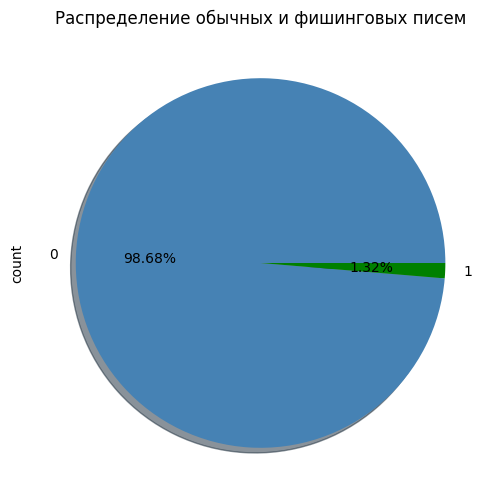

In [7]:
df['label'].value_counts().sort_index().plot(kind='pie', autopct='%.2f%%', shadow=True, figsize=(11, 6), colors=['steelblue', 'green'])
plt.title('Распределение обычных и фишинговых писем')
plt.show()

2. Целевая переменная. <br>
   Мы видим, что целевая переменная имеет __ОЧЕНЬ__ сильный дизбаланс между значениями 0 и 1, единиц __лишь около 1,32%__ от общего числа писем.
   <br>Это означает две вещи,
   - Во-первых, что если наша модель будет __просто предсказывать 0 ВСЕГДА__, то мы получим точность __98,68%__. Значит показатели точности это не единственное, на что нужно смотреть и нам надо будет также анализировать __матрицу несоответствий__.
   - Во-вторых, для тренировки модели используем __веса классов__. Validation и test не балансируем.

In [8]:
df.num_unique_domains.value_counts()

num_unique_domains
0      431424
1       62638
2       14525
3        6421
4        3912
        ...  
77          2
51          2
123         1
524         1
46          1
Name: count, Length: 82, dtype: int64

In [9]:
numeric_columns =['num_words', 'num_unique_words', 'num_stopwords', 'num_links',
       'num_unique_domains', 'num_email_addresses', 'num_spelling_errors',
       'num_urgent_keywords']
all_columns =['num_words', 'num_unique_words', 'num_stopwords', 'num_links',
       'num_unique_domains', 'num_email_addresses', 'num_spelling_errors',
       'num_urgent_keywords', 'label']

In [10]:
FEATURES = numeric_columns
if set(df.columns) != set(all_columns):
    raise ValueError('Неожиданный набор столбцов')
df = df[all_columns]
if df.empty or df.isna().any().any():
    raise ValueError('Данные пусты или содержат пропуски')
if not all(pd.api.types.is_numeric_dtype(df[c]) for c in all_columns):
    raise ValueError('Все столбцы должны быть числовыми')
if not np.isfinite(df.to_numpy()).all():
    raise ValueError('Обнаружены бесконечные значения')
values = df[numeric_columns].to_numpy()
if (values < 0).any() or (values != np.floor(values)).any():
    raise ValueError('Счётчики должны быть неотрицательными целыми числами')
if set(df.label.unique()) != {0, 1}:
    raise ValueError('В label должны быть оба класса: 0 и 1')
print('Проверки данных пройдены')

Проверки данных пройдены


3. Выбросы и IQR (Interquantile Range)<br>
   У нас много данных, но не будем удалять ту часть, где чересчур много слов или, наоборот, пустые письма: они тоже могут быть фишинговыми. <br>
   Обращаю внимание, что делать IQR нельзя в столбцах, где 25 и 75 процентиль - нули, потому что тогда мы можем потерять важную информацию

Одинаковые наборы признаков оставляем в одной выборке, чтобы train, validation и test не пересекались.

Проверим, что мы не потеряли при разбиении непропорционально много фишинговых писем:

In [11]:
from sklearn.model_selection import train_test_split

group_ids = df.groupby(numeric_columns, sort=False).ngroup()
groups = pd.DataFrame({'group': group_ids, 'label': df.label}).groupby('group').label.agg(['size', 'min', 'max'])
print('Полных повторов строк:', df.duplicated().sum())
print('Уникальных наборов признаков:', len(groups))
print('Групп с разными метками:', (groups['min'] != groups['max']).sum())

train_groups, holdout_groups = train_test_split(
    groups.index.to_numpy(), test_size=0.4, random_state=42,
    stratify=groups['max'].to_numpy()
)
val_groups, test_groups = train_test_split(
    holdout_groups, test_size=0.5, random_state=42,
    stratify=groups.loc[holdout_groups, 'max'].to_numpy()
)
assert set(train_groups).isdisjoint(val_groups)
assert set(train_groups).isdisjoint(test_groups)
assert set(val_groups).isdisjoint(test_groups)

df_train = df.loc[group_ids.isin(train_groups)].copy()
df_val = df.loc[group_ids.isin(val_groups)].copy()
df_test = df.loc[group_ids.isin(test_groups)].copy()
assert len(df_train) + len(df_val) + len(df_test) == len(df)

pd.DataFrame([
    {'выборка': name, 'строк': len(part), 'фишинговых': int(part.label.sum()),
     'доля фишинга': part.label.mean()}
    for name, part in [('train', df_train), ('validation', df_val), ('test', df_test)]
])

Полных повторов строк: 319794
Уникальных наборов признаков: 204403
Групп с разными метками: 649


,выборка,строк,фишинговых,доля фишинга
0,train,311504,4193,0.013461
1,validation,108009,1381,0.012786
2,test,105333,1375,0.013054


Порядок, мы не потеряли обычные и фишинговые письма при разбиении.

In [12]:
df_train[numeric_columns].describe()

,num_words,num_unique_words,num_stopwords,num_links,num_unique_domains,num_email_addresses,num_spelling_errors,num_urgent_keywords
count,311504.000000,311504.000000,311504.000000,311504.000000,311504.000000,311504.000000,311504.000000,311504.000000
mean,275.441330,124.194935,80.071386,0.893241,0.345822,2.131237,24.062339,0.249772
std,828.753363,187.564207,249.637585,5.392436,1.567595,13.606552,66.059026,0.562631
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,49.000000,39.000000,13.000000,0.000000,0.000000,0.000000,2.000000,0.000000
50%,122.000000,80.000000,35.000000,0.000000,0.000000,0.000000,8.000000,0.000000
75%,272.000000,146.000000,80.000000,0.000000,0.000000,1.000000,23.000000,0.000000
max,46124.000000,6926.000000,14148.000000,275.000000,123.000000,1150.000000,4177.000000,6.000000


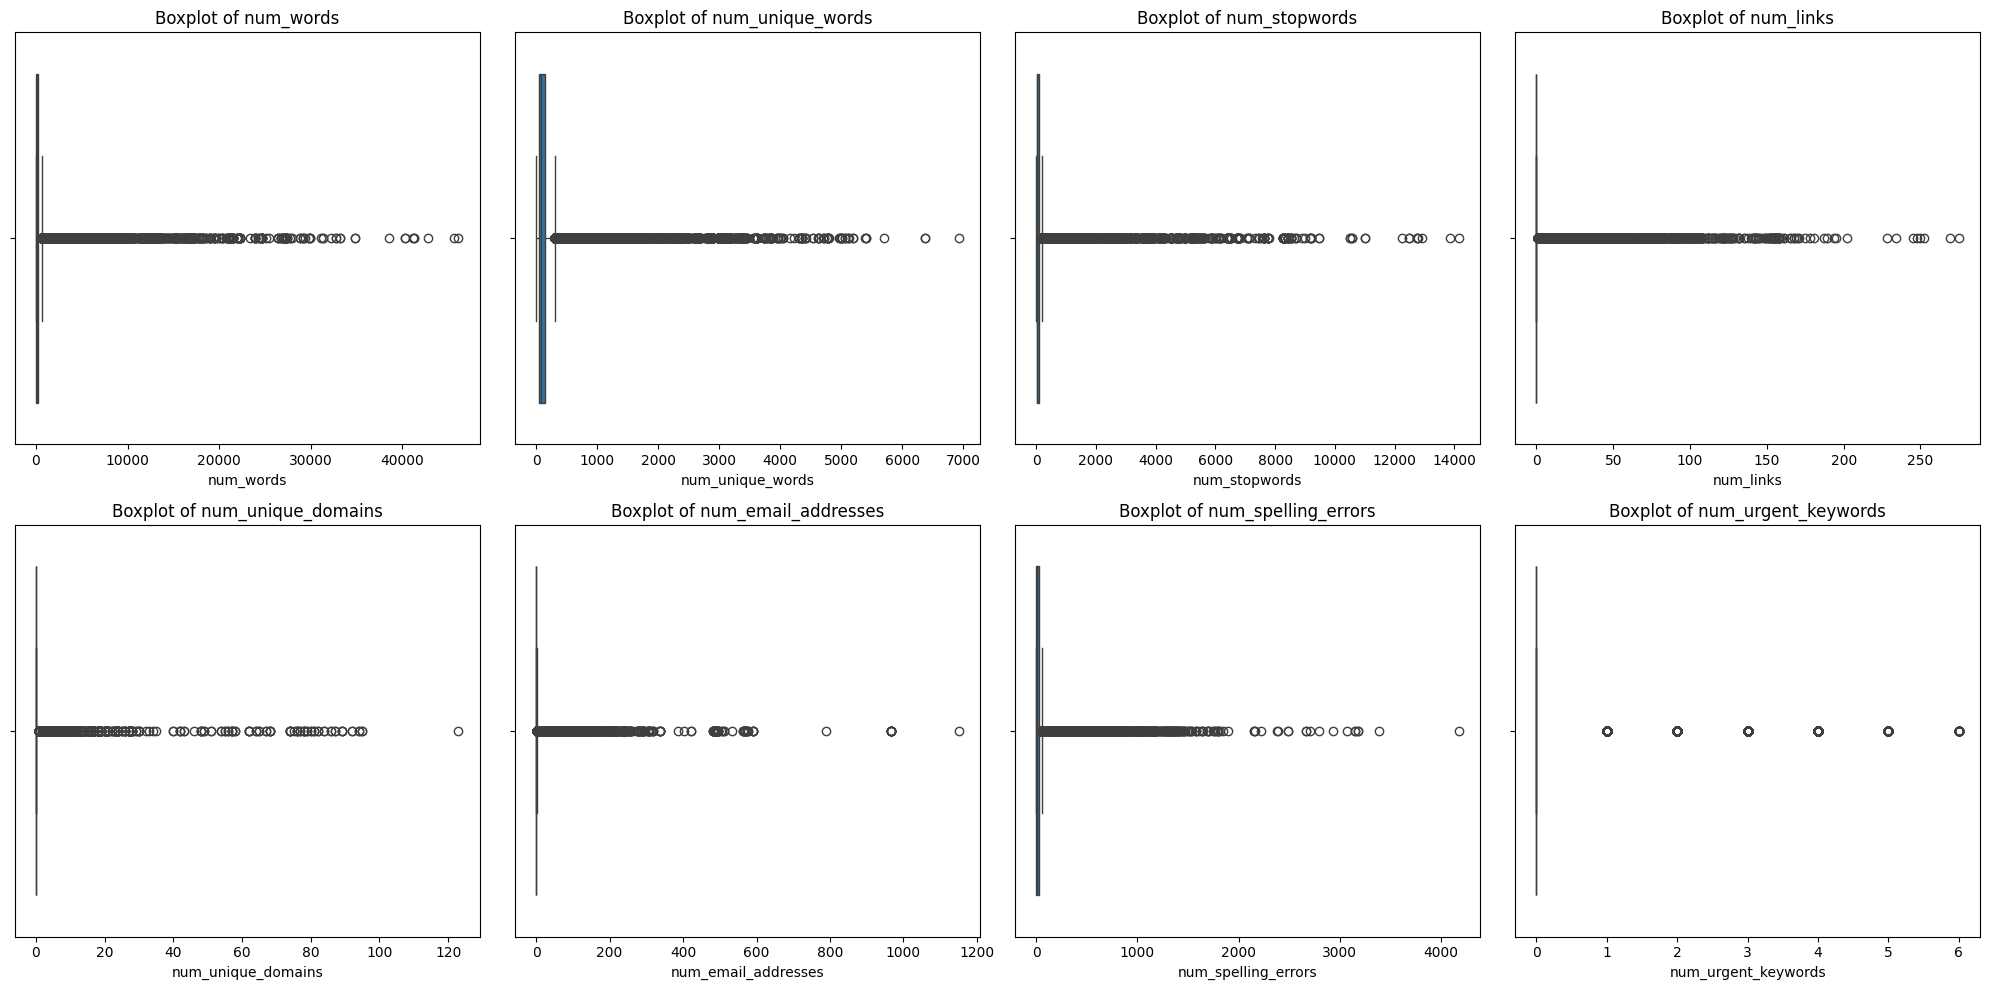

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for i, col in enumerate(numeric_columns):
    sns.boxplot(x=df_train[col], ax=axes[i])
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
plt.tight_layout()
plt.show()

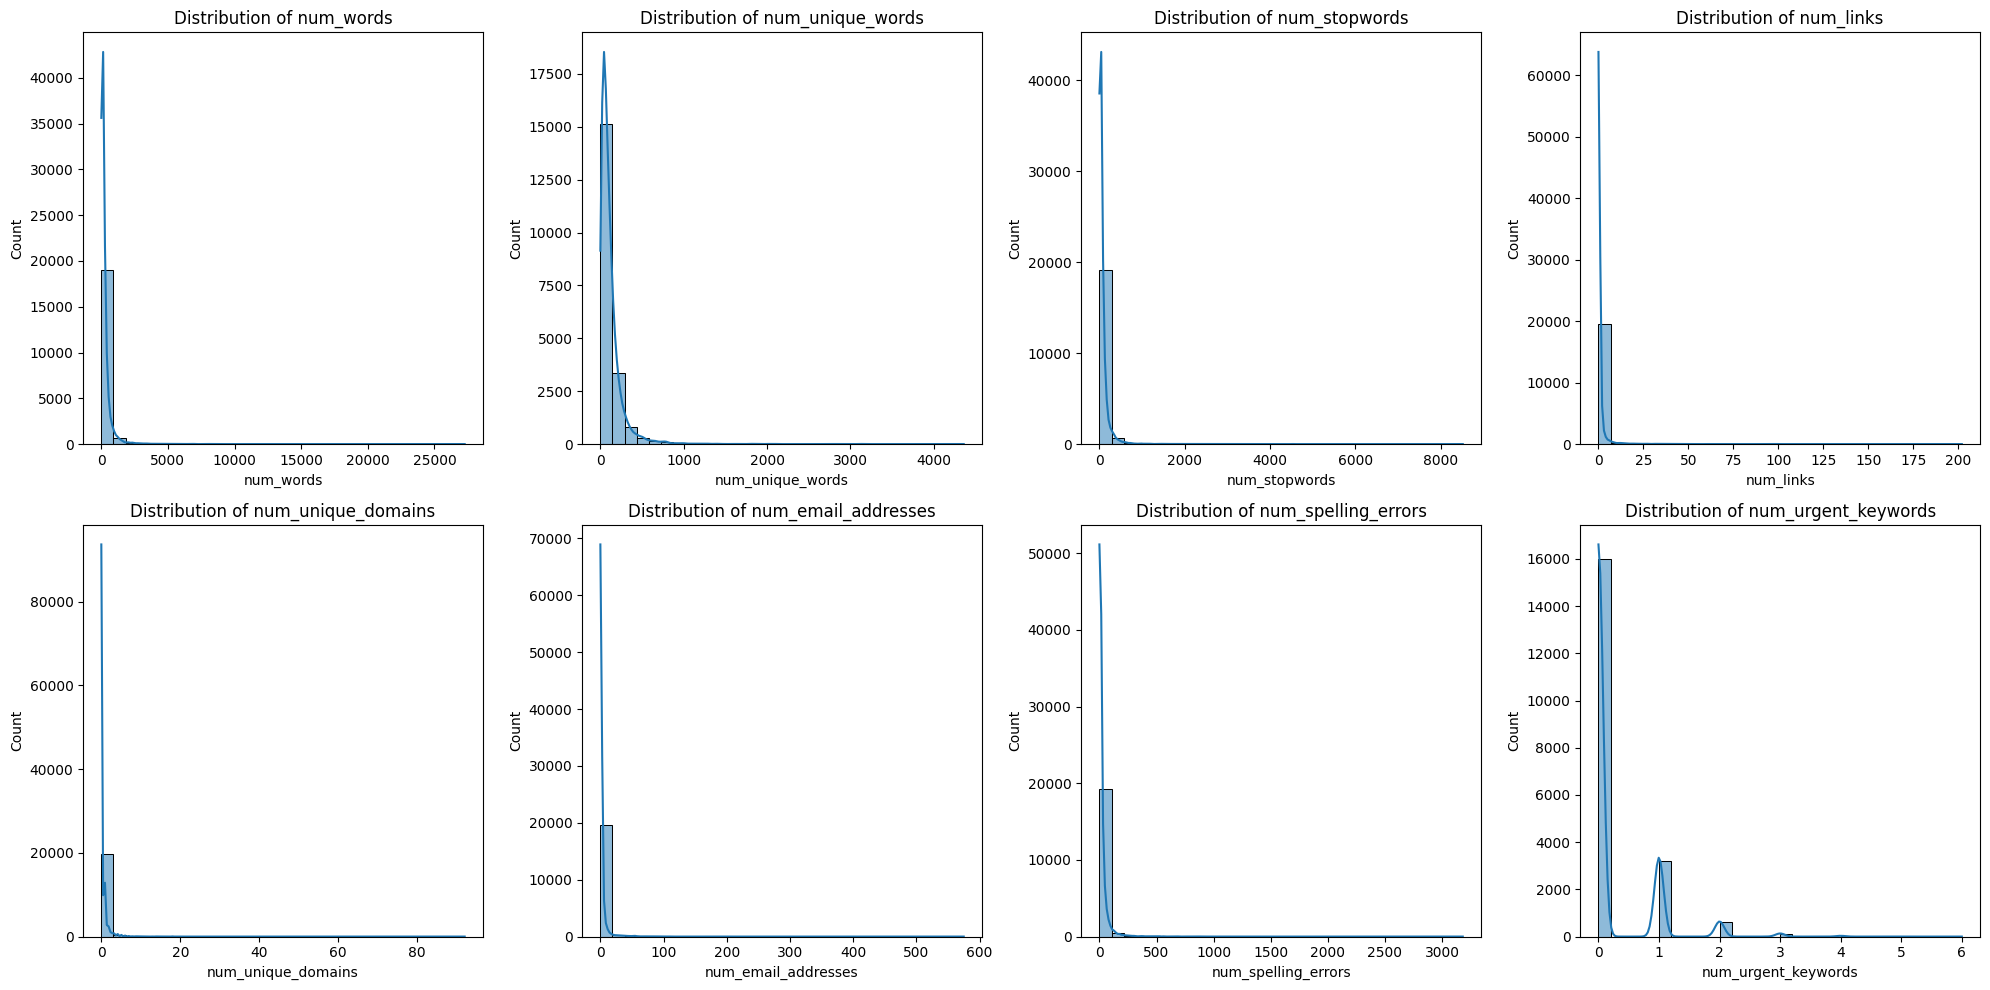

In [14]:
# Для быстрого построения графиков возьмём до 20 000 строк из train.
# На обучение это не влияет: модели получат весь train.
plot_df = df_train.sample(n=min(20000, len(df_train)), random_state=42)
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for i, col in enumerate(numeric_columns):
    sns.histplot(plot_df[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

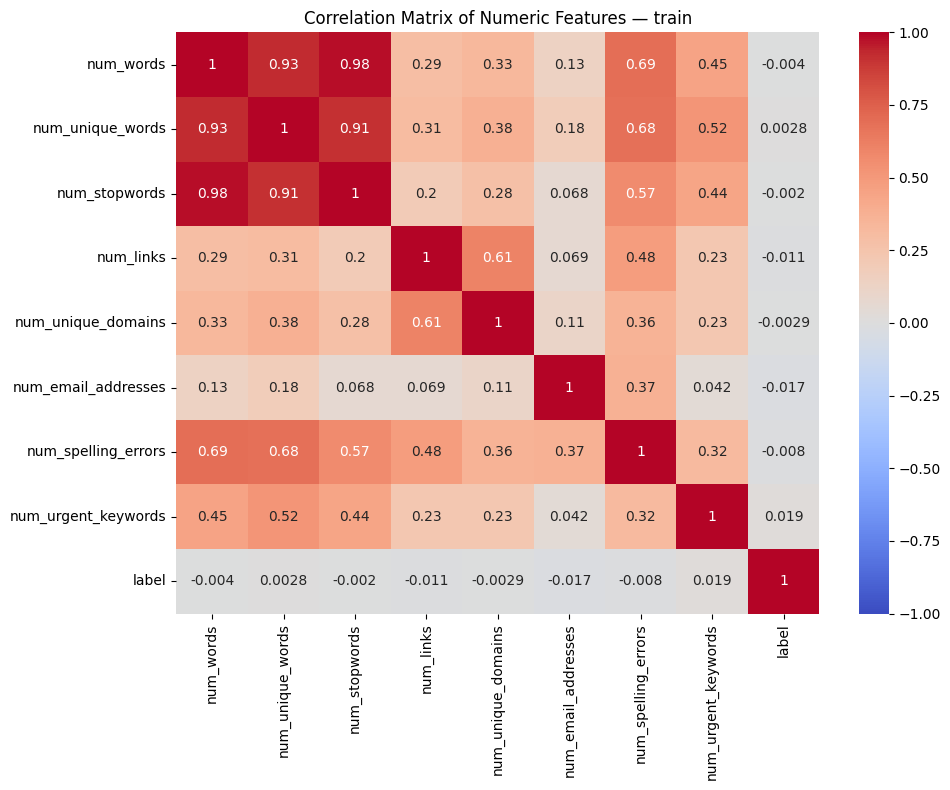

In [15]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_train[all_columns].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numeric Features — train')
plt.tight_layout()
plt.show()

Как видно, нет какой-то удобной линейной корреляции, которая являлась бы хорошим маркером фишинговых писем. Это печально(

In [16]:
df_train[numeric_columns].skew().sort_values(ascending=False)

num_email_addresses    30.733694
num_unique_domains     28.205180
num_stopwords          21.044468
num_words              19.988447
num_links              16.471114
num_spelling_errors    13.768000
num_unique_words        9.439072
num_urgent_keywords     2.808487
dtype: float64

# Моделирование

Как уже было упомянуто, нам нельзя оценивать модель только по accuracy, потому что из-за большой непропорциональности, модель будет иметь высокую точность ~98,68%, даже если будет предсказывать 0 всегда. Поэтому используем веса классов, а масштабирование обучим только на train.

Я использую и сравню 4 модели: __Logistic Regression__, __Random Forest__, __ExtraTrees__ и __HistGradientBoosting__

In [17]:
import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score, precision_recall_curve, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    PrecisionRecallDisplay
)

X_train = df_train[numeric_columns]
y_train = df_train['label']
X_val = df_val[numeric_columns]
y_val = df_val['label']
X_test = df_test[numeric_columns]
y_test = df_test['label']

In [18]:
def add_features(X):
    X = pd.DataFrame(X, columns=FEATURES).astype(float).copy()
    words = X['num_words'].clip(lower=1)
    for col in FEATURES[1:]:
        X[col + '_per_word'] = X[col] / words
    X['links_per_domain'] = X['num_links'] / X['num_unique_domains'].clip(lower=1)
    X['words_per_unique'] = X['num_words'] / X['num_unique_words'].clip(lower=1)
    X['empty_email'] = (X['num_words'] == 0).astype(float)
    # Эти признаки не требуют fit и не используют целевую переменную.
    return X

In [19]:
def candidates():
    feature_step = lambda: FunctionTransformer(add_features, validate=False)
    models = {
        'RF previous': RandomForestClassifier(n_estimators=120, class_weight='balanced', max_depth=18, min_samples_leaf=5, n_jobs=2, random_state=42),
        'RF + ratios': make_pipeline(feature_step(), RandomForestClassifier(n_estimators=160, class_weight='balanced', max_depth=20, min_samples_leaf=5, n_jobs=2, random_state=42)),
        'ExtraTrees + ratios': make_pipeline(feature_step(), ExtraTreesClassifier(n_estimators=160, class_weight='balanced', max_depth=22, min_samples_leaf=5, n_jobs=2, random_state=42)),
        'Logistic + log/ratios': make_pipeline(feature_step(), FunctionTransformer(np.log1p, validate=False), StandardScaler(), LogisticRegression(class_weight='balanced',max_iter=2000,random_state=42)),
    }
    # early_stopping=False: внутренний случайный split мог бы разделить одинаковые группы.
    for weight in [1, 10, 75]:
        models[f'HistGB ratios weight={weight}'] = make_pipeline(feature_step(), HistGradientBoostingClassifier(
            max_iter=250, max_leaf_nodes=31, learning_rate=.07, l2_regularization=10,
            min_samples_leaf=30, class_weight={0:1, 1:weight}, early_stopping=False, random_state=42))
    return models

models = candidates()

Выбираем модель с минимальной долей ложных тревог среди обычных писем при recall ≥ 80% на validation. Пороги выбираются только по validation.

In [20]:
def threshold_at_recall(y, scores, target):
    p, r, t = precision_recall_curve(y, scores)
    valid = np.flatnonzero(r[:-1] >= target)
    # Наибольший порог с нужным recall: наименьшее число срабатываний.
    return float(t[valid[-1]])

def measure(y, scores, threshold):
    pred = scores >= threshold
    tn, fp, fn, tp = map(int, confusion_matrix(y, pred, labels=[0, 1]).ravel())
    return {'threshold': float(threshold), 'recall': tp / (tp + fn),
            'precision': tp / (tp + fp) if tp + fp else 0.,
            'FPR': fp / (fp + tn), 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'AP': float(average_precision_score(y, scores)),
            'alert_fraction': (tp + fp) / len(y)}

In [21]:
TARGET_RECALL = 0.80
val_scores = {}
validation_rows = []

for model_name, model in models.items():
    print(f'\nTraining {model_name}...')
    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed_time = time.perf_counter() - start_time

    scores = model.predict_proba(X_val)[:, 1]
    val_scores[model_name] = scores
    threshold = threshold_at_recall(y_val, scores, TARGET_RECALL)
    validation_rows.append({
        'model': model_name, **measure(y_val, scores, threshold),
        'fit_seconds': elapsed_time
    })
    print(f'{model_name} training completed in {elapsed_time:.2f} seconds.')

validation_results = pd.DataFrame(validation_rows).sort_values(['FPR', 'AP'], ascending=[True, False])
validation_results[['model', 'AP', 'precision', 'recall', 'FPR', 'threshold', 'fit_seconds']]


Training RF previous...
RF previous training completed in 14.90 seconds.

Training RF + ratios...
RF + ratios training completed in 35.91 seconds.

Training ExtraTrees + ratios...
ExtraTrees + ratios training completed in 16.48 seconds.

Training Logistic + log/ratios...
Logistic + log/ratios training completed in 0.93 seconds.

Training HistGB ratios weight=1...
HistGB ratios weight=1 training completed in 4.53 seconds.

Training HistGB ratios weight=10...
HistGB ratios weight=10 training completed in 4.53 seconds.

Training HistGB ratios weight=75...
HistGB ratios weight=75 training completed in 4.68 seconds.


,model,AP,precision,recall,FPR,threshold,fit_seconds
6,HistGB ratios weight=75,0.244748,0.041737,0.800145,0.237930,0.403643,4.675806
5,HistGB ratios weight=10,0.263752,0.041498,0.800145,0.239365,0.092185,4.525734
4,HistGB ratios weight=1,0.274068,0.041442,0.800145,0.239703,0.011076,4.530941
2,ExtraTrees + ratios,0.254781,0.038679,0.800869,0.257793,0.413193,16.476407
1,RF + ratios,0.265973,0.037600,0.800869,0.265493,0.132860,35.913160
0,RF previous,0.223736,0.032798,0.801593,0.306158,0.225229,14.899878
3,Logistic + log/ratios,0.064757,0.025762,0.800145,0.391895,0.468279,0.929526


Лучшая модель по выбранному правилу: HistGB ratios weight=75


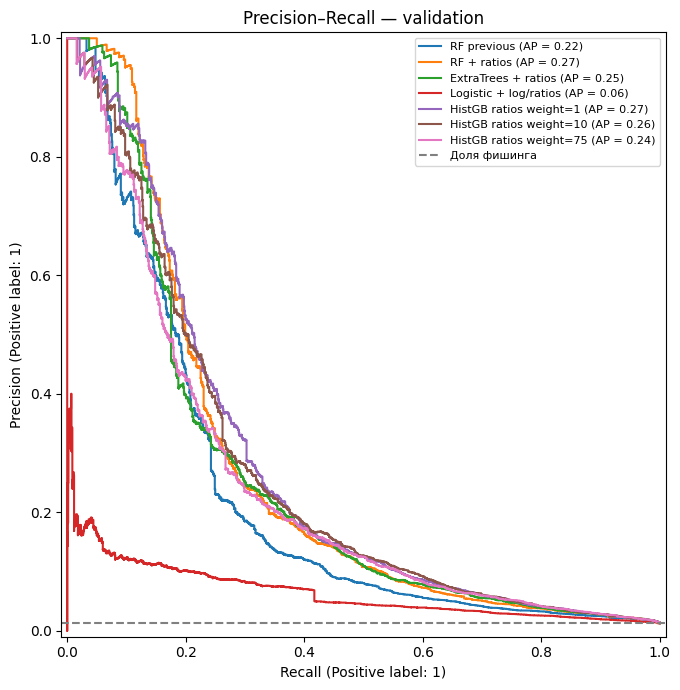

In [22]:
best_name = validation_results.iloc[0]['model']
best_model = models[best_name]
print('Лучшая модель по выбранному правилу:', best_name)

fig, ax = plt.subplots(figsize=(10, 7))
for model_name, scores in val_scores.items():
    PrecisionRecallDisplay.from_predictions(y_val, scores, name=model_name, ax=ax)
ax.axhline(y_val.mean(), linestyle='--', color='gray', label='Доля фишинга')
ax.set_title('Precision–Recall — validation')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [23]:
thresholds = {
    'recall_60': threshold_at_recall(y_val, val_scores[best_name], 0.60),
    'recall_80': threshold_at_recall(y_val, val_scores[best_name], 0.80),
    'recall_90': threshold_at_recall(y_val, val_scores[best_name], 0.90)
}
fpr, tpr, possible_thresholds = roc_curve(y_val, val_scores[best_name], drop_intermediate=False)
feasible = np.flatnonzero(fpr <= 0.05)
thresholds['FPR_5pct'] = float(possible_thresholds[feasible[-1]])

pd.DataFrame([
    {'режим': name, **measure(y_val, val_scores[best_name], threshold)}
    for name, threshold in thresholds.items()
])[['режим', 'threshold', 'precision', 'recall', 'FPR']]

,режим,threshold,precision,recall,FPR
0,recall_60,0.618774,0.083141,0.600290,0.085737
1,recall_80,0.403643,0.041737,0.800145,0.237930
2,recall_90,0.261961,0.028432,0.900072,0.398357
3,FPR_5pct,0.716762,0.117257,0.512672,0.049987


Test уже просматривался раньше: это повторное сравнение, для независимой проверки нужны новые письма.

In [24]:
test_scores = best_model.predict_proba(X_test)[:, 1]
test_rows = [
    {'режим': name, **measure(y_test, test_scores, threshold)}
    for name, threshold in thresholds.items()
]

# Прежний лес с прежним F1-порогом: сравнение с первой исправленной версией.
# Порог зафиксирован для исходного CSV; при замене данных его смысл меняется.
old_scores = models['RF previous'].predict_proba(X_test)[:, 1]
baseline = measure(y_test, old_scores, 0.7017495182110984)
test_results = pd.DataFrame([{'режим': 'Предыдущий RF / F1', **baseline}] + test_rows)
test_results[['режим', 'precision', 'recall', 'FPR', 'TP', 'FP', 'FN', 'TN']]

,режим,precision,recall,FPR,TP,FP,FN,TN
0,Предыдущий RF / F1,0.320802,0.186182,0.005214,256,542,1119,103416
1,recall_60,0.078825,0.605091,0.093528,832,9723,543,94235
2,recall_80,0.042160,0.816000,0.245205,1122,25491,253,78467
3,recall_90,0.029393,0.917818,0.400873,1262,41674,113,62284
4,FPR_5pct,0.113257,0.498909,0.051665,686,5371,689,98587


In [25]:
MODE = 'recall_80'  # Можно выбрать recall_60, recall_90 или FPR_5pct.
y_pred = (test_scores >= thresholds[MODE]).astype(int)
print(f'Performance of {best_name}; mode: {MODE}')
print(classification_report(y_test, y_pred, target_names=['Обычное', 'Фишинг'], digits=4, zero_division=0))

Performance of HistGB ratios weight=75; mode: recall_80
              precision    recall  f1-score   support

     Обычное     0.9968    0.7548    0.8591    103958
      Фишинг     0.0422    0.8160    0.0802      1375

    accuracy                         0.7556    105333
   macro avg     0.5195    0.7854    0.4696    105333
weighted avg     0.9843    0.7556    0.8489    105333



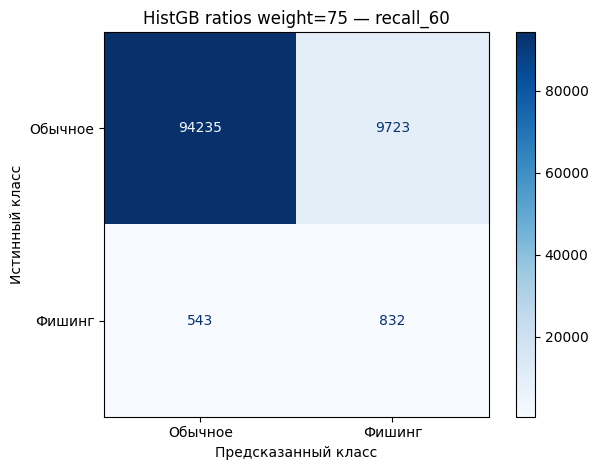

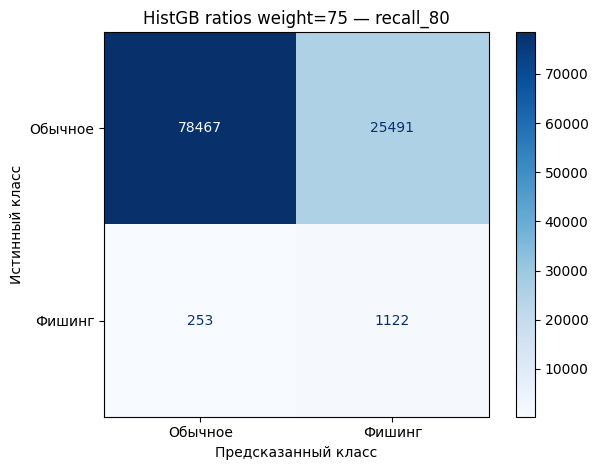

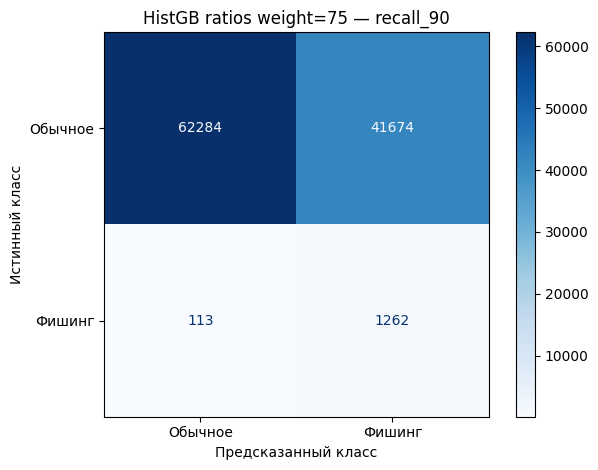

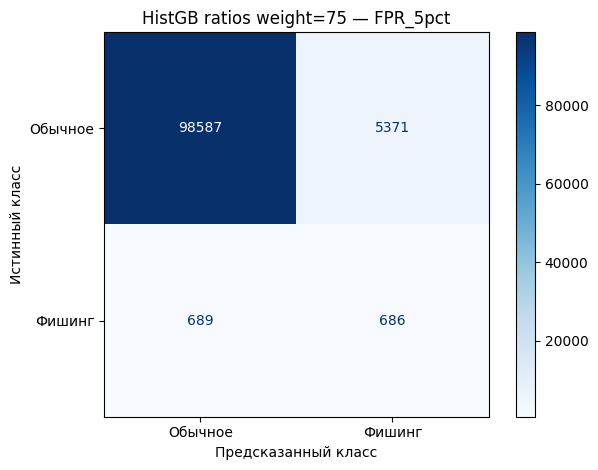

In [26]:
for mode, threshold in thresholds.items():
    predictions = (test_scores >= threshold).astype(int)
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Обычное', 'Фишинг'])
    disp.plot(cmap=plt.cm.Blues, values_format='d')
    plt.title(f'{best_name} — {mode}')
    plt.xlabel('Предсказанный класс')
    plt.ylabel('Истинный класс')
    plt.tight_layout()
    plt.show()

# Вывод

- Как видим из информации о производительности и матриц несоответствий, __HistGradientBoosting__ раскрывает __81,6%__ фишинговых писем, но __очень__ часто называет фишинговыми обычные письма: __24,5%__ из них. Среди срабатываний верны только __4,2%__.
- По выбранному правилу HistGradientBoosting является __лучшим__ методом для предсказания в нашем случае, но большое количество ложных тревог всё ещё остаётся проблемой.
- В режиме __FPR_5pct__ модель раскрывает __49,9%__ фишинговых писем и помечает как фишинг __5,2%__ обычных писем.


Несмотря на то что можно было добиться более высокой accuracy просто выставляя письму 0 __всегда__, я добился того чтобы модель раскрывала фишинговые письма в БОЛЬШЕЙ части случаев методом HistGradientBoosting, ценой того что 24,5% обычных писем были помечены как фишинг.